In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Aufgabe 1: Bestimmung der Tonhöhe eines akustischen Signals

Einlesen der Messdaten

In [4]:
data = pd.read_csv(
    "data/ton2.csv",
    sep=";",
    decimal=",",
    skiprows=3,
    header=None
)

zeit = data[0].to_numpy()
signal = data[1].to_numpy()

print(data.head())

           0         1
0 -25.007999  2.426796
1 -25.002999  2.053396
2 -24.997999  2.426796
3 -24.992999  1.492987
4 -24.987999  1.679995


### Graphische Darstellung des Signals

Das aufgenommene Signal wird im Zeitbereich dargestellt.

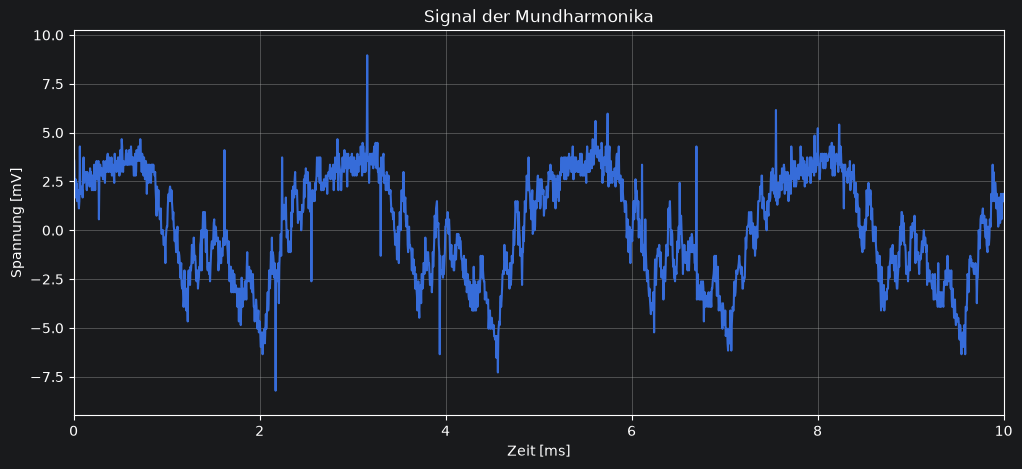

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(zeit, signal)

plt.xlabel("Zeit [ms]")
plt.ylabel("Spannung [mV]")
plt.title("Signal der Mundharmonika")
plt.grid()
plt.xlim(0, 10)
plt.show()

### Bestimmung der Grundperiode und Grundfrequenz


In [7]:
# Grundperiode in Sekunden
T0 = 2.5 / 1000

# Grundfrequenz
f0 = 1 / T0

print("Grundperiode:", T0 * 1000, "ms")
print("Grundfrequenz:", f0, "Hz")

Grundperiode: 0.0025 s
Grundfrequenz: 400.0 Hz


### Bestimmung der Signalparameter

Es werden die Signallänge M, das Abtastintervall,
die Abtastfrequenz und die Signaldauer bestimmt.

In [8]:
# Signallänge
M = len(signal)

# Abtastintervall in Sekunden
dt = np.mean(np.diff(zeit)) / 1000

# Abtastfrequenz
fs = 1 / dt

# Signaldauer
T = M * dt

print("Signallänge:", M)
print("Abtastintervall:", dt, "s")
print("Abtastfrequenz:", fs, "Hz")
print("Signaldauer:", T, "s")

Signallänge: 10004
Abtastintervall: 4.999999873038088e-06 s
Abtastfrequenz: 200000.00507847662 Hz
Signaldauer: 0.05001999872987303 s


### Fouriertransformation und Amplitudenspektrum

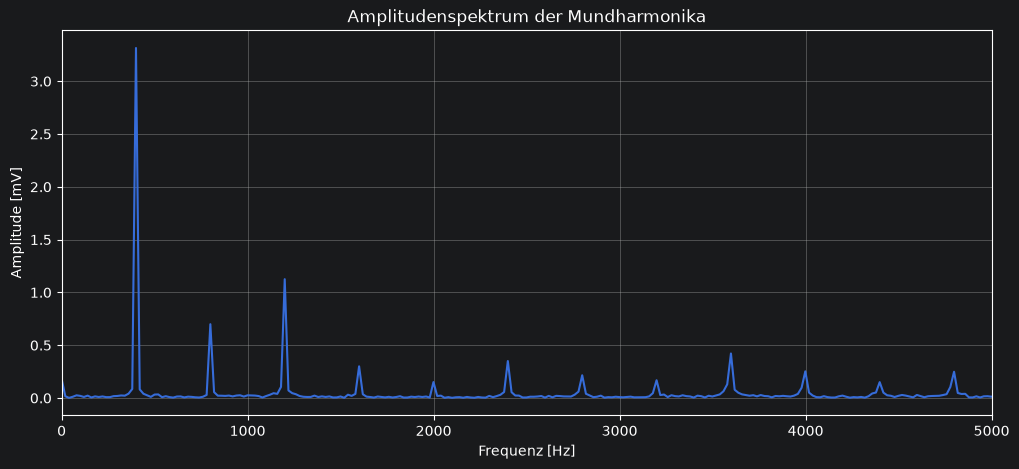

In [10]:
# Fouriertransformation
fourier = np.fft.fft(signal)

# Einseitiges Amplitudenspektrum
amplitude = 2 / M * np.abs(fourier[:(M + 1) // 2])
amplitude[0] /= 2

# Frequenzachse in Hertz
frequenz = np.arange(len(amplitude)) / (M * dt)

plt.figure(figsize=(12, 5))

plt.plot(frequenz, amplitude)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude [mV]")
plt.title("Amplitudenspektrum der Mundharmonika")
plt.grid()
plt.xlim(0, 5000)
plt.show()

### Bestimmung der Grundfrequenz im Spektrum

Die Grundfrequenz wird im Amplitudenspektrum
identifiziert. Anschließend werden ihre Frequenz
und Amplitude bestimmt.

In [11]:
# Index der maximalen Amplitude (ohne Gleichanteil)
index = np.argmax(amplitude[1:]) + 1

# Dominante Frequenz und Amplitude
f0_fft = frequenz[index]
A0 = amplitude[index]

print("Frequenz:", f0_fft, "Hz")
print("Amplitude:", A0, "mV")

Frequenz: 399.8400741273023 Hz
Amplitude: 3.314505609656183 mV
